# 🌦️ Sistem Prediksi Musim Hujan Beresolusi Tinggi Tingkat Kecamatan di Kabupaten Kebumen
### *Benchmark Kompetitif Terhadap Prakiraan Regional Zona Musim (ZOM) BMKG Berbasis Machine Learning & Multi-Sensor Reanalisis*

---

## 📌 Latar Belakang & Urgensi Riset
Badan Meteorologi, Klimatologi, dan Geofisika (BMKG) secara rutin merilis Prakiraan Awal Musim Hujan (AMH) setiap tahunnya. Namun, cakupan prakiraan BMKG berbasis pada **Zona Musim (ZOM)** yang berskala makro/regional. Di Kabupaten Kebumen, wilayah kabupaten kerap kali hanya dipukul rata dalam 1-2 ZOM regional, sehingga menghasilkan prakiraan tunggal (misal: "Awal Musim Hujan Kebumen jatuh pada Oktober II").

Padahal, secara fisik, Kabupaten Kebumen memiliki gradien morfologi dan topografi yang sangat kontras:
1. **Zona Pegunungan Utara & Perbukitan Antiklinorium Karangsambung-Sadang:** Ketinggian hingga >500 mdpl yang memicu pengangkatan orografis awan konvektif secara dini.
2. **Zona Dataran Aluvial Lembah Sungai Luk Ulo & dataran tengah:** Wilayah sentra pertanian irigasi teknis.
3. **Zona Pesisir Pantai Selatan (Urutsewu):** Terbuka langsung ke Samudra Hindia dengan rezim angin darat-laut yang khas.

Notebook ini menyajikan **Sistem Prediksi Musim Hujan Tingkat Kecamatan (26 Kecamatan)** menggunakan integrasi data satelit presipitasi resolusi tinggi (CHIRPS & GSMaP), reanalisis atmosferik (ERA5-Land), indeks osilasi iklim global (NOAA ENSO ONI & IOD DMI), dan machine learning dengan protokol validasi spasial temporal **Leave-One-Year-Out (LOYO)** 2000–2025.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, confusion_matrix, classification_report
from IPython.display import Image, display

# Setup direktori proyek
BASE_DIR = Path(r"d:\Github\Projek_Downscale")
DATA_DIR = BASE_DIR / "prediksi_musim" / "data"
PLOTS_DIR = BASE_DIR / "prediksi_musim" / "plots_16_9"
GEOJSON_PATH = BASE_DIR / "33.05_kecamatan.geojson"

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✅ Library berhasil dimuat. Siap menganalisis data prediksi musim Kebumen.")


✅ Library berhasil dimuat. Siap menganalisis data prediksi musim Kebumen.


## 1. Baseline Klimatologi Normal Awal Musim Hujan (AMH) 26 Kecamatan
Sesuai standar operasional BMKG, **Awal Musim Hujan (AMH)** ditetapkan apabila:
- Suatu dasarian (10 harian) memiliki curah hujan $\ge 50\text{ mm}$, dan
- Diikuti oleh dasarian-dasarian berikutnya yang juga konsisten $\ge 50\text{ mm}$.

Berdasarkan analisis 26 tahun (2000–2025), berikut adalah profil dasar normal klimatologi tiap kecamatan:


In [2]:
# Memuat tabel normal klimatologi
df_norm = pd.read_csv(DATA_DIR / "normal_klimatologi_amh_kebumen.csv")
gdf_kec = gpd.read_file(GEOJSON_PATH)

print(f"Total Kecamatan Terpetakan: {len(df_norm)} Kecamatan")
display(df_norm[['kecamatan', 'normal_amh_label', 'mean_amh_dasarian', 'terawal_amh_label', 'terlambat_amh_label', 'normal_total_hujan_mh_mm']].head(10))


Total Kecamatan Terpetakan: 26 Kecamatan


,kecamatan,normal_amh_label,mean_amh_dasarian,terawal_amh_label,terlambat_amh_label,normal_total_hujan_mh_mm
0,Ayah,Okt I,28.15,Agu I,Des I,2187.4
1,Buayan,Okt I,28.12,Agu I,Des I,2147.7
2,Puring,Okt II,28.42,Agu I,Des I,2155.5
3,Petanahan,Okt II,28.62,Agu I,Des I,2251.3
4,Klirong,Okt II,28.73,Agu I,Des I,2217.5
5,Buluspesantren,Okt III,29.15,Agu I,Des I,2087.8
6,Ambal,Okt III,29.62,Agu III,Des I,1922.9
7,Mirit,Okt III,29.85,Agu III,Des I,1771.1
8,Prembun,Okt III,29.65,Agu III,Des I,2022.8
9,Kutowinangun,Okt III,29.35,Agu III,Des I,2121.3


### Temuan Signifikan: 3 Kluster Mikro-ZOM di Kebumen
Analisis data multi-dekade membuktikan bahwa Kebumen memiliki gradien kedatangan musim hujan sekitar **20 hari** dari utara ke selatan:
1. **Kluster Pegunungan & Perbukitan Utara (Okt I / Dasarian 28):** Karanggayam, Sadang, Karangsambung, Sempor, Gombong, Rowokele, Ayah. Total curah hujan musim hujan mencapai **2.800 – 2.960 mm**.
2. **Kluster Dataran Aluvial Tengah (Okt II / Dasarian 29):** Puring, Petanahan, Klirong, Kebumen, Alian, Adimulyo, Kuwarasan. Total curah hujan **2.200 – 2.350 mm**.
3. **Kluster Pesisir & Dataran Timur (Okt III / Dasarian 30):** Mirit, Ambal, Buluspesantren, Bonorowo, Prembun, Kutowinangun. Total curah hujan **1.700 – 1.950 mm**.


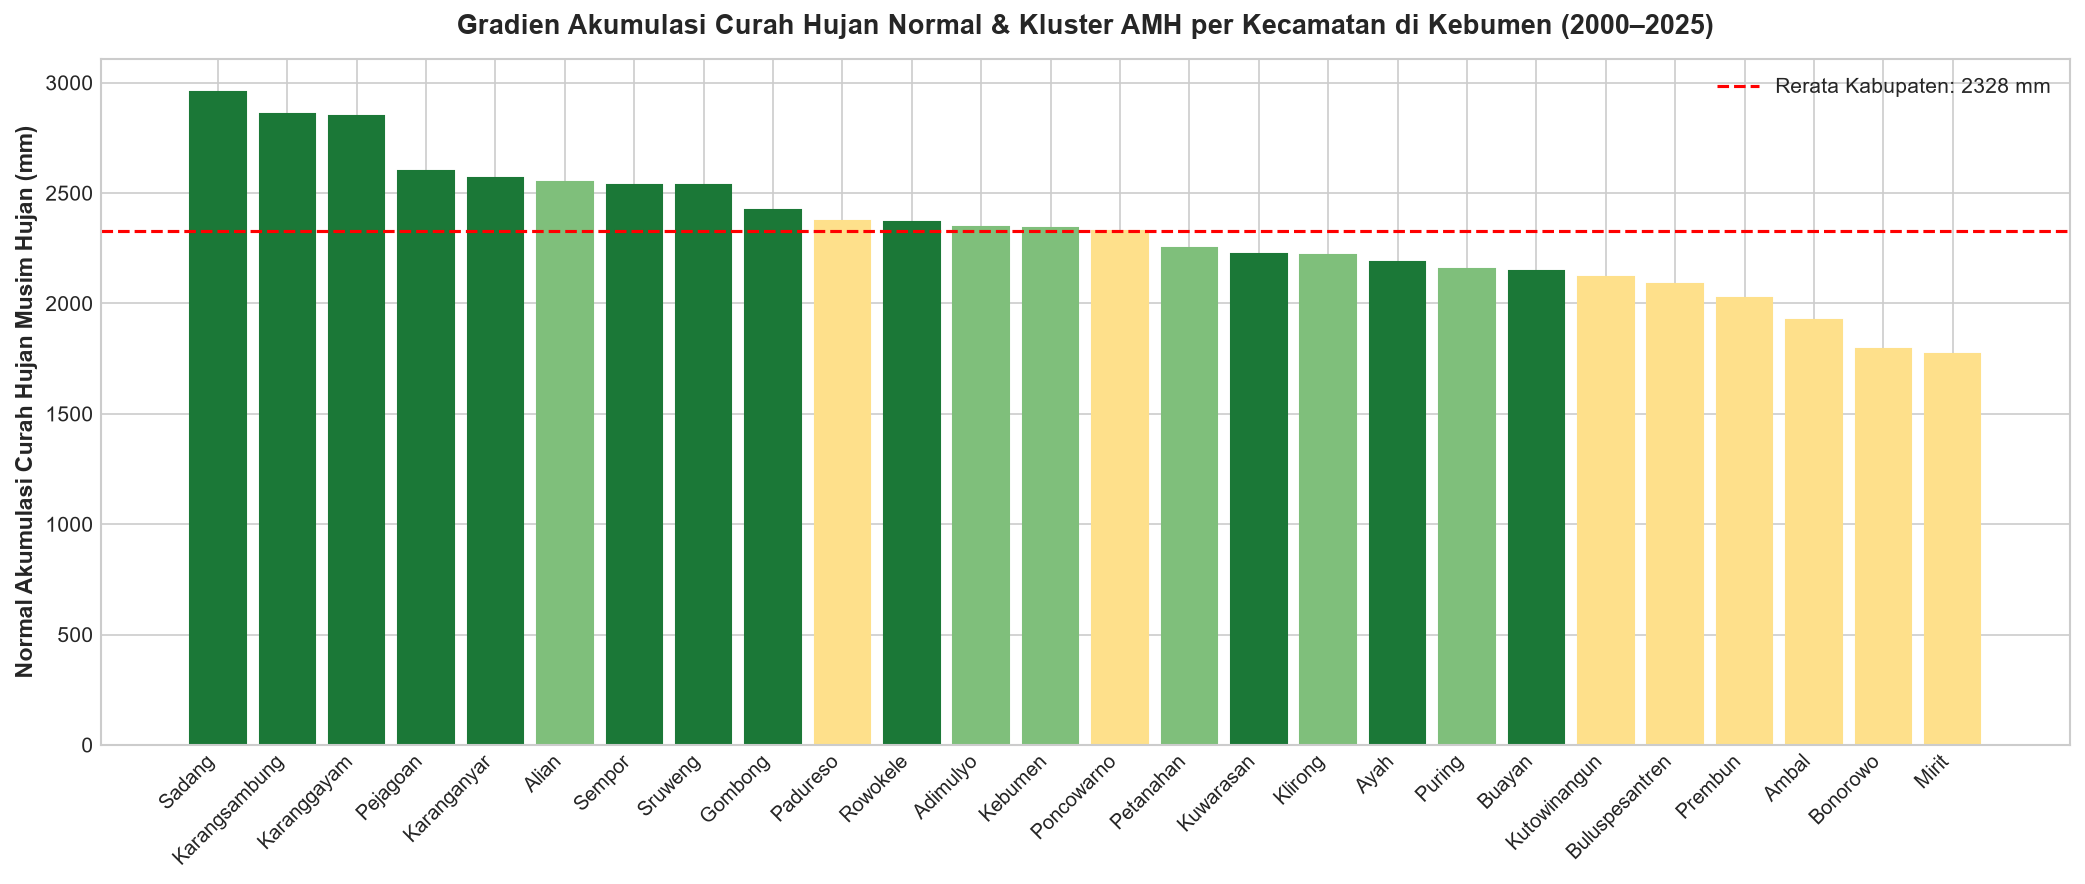

In [3]:
# Visualisasi Distribusi Total Curah Hujan Normal Musim Hujan per Kecamatan
fig, ax = plt.subplots(figsize=(14, 6), dpi=150)
df_sorted = df_norm.sort_values(by='normal_total_hujan_mh_mm', ascending=False)
bars = ax.bar(df_sorted['kecamatan'], df_sorted['normal_total_hujan_mh_mm'], color='#2b83ba', edgecolor='#111111')

# Pewarnaan berdasarkan zona AMH
for i, (_, row) in enumerate(df_sorted.iterrows()):
    if row['normal_amh_label'] == 'Okt I':
        bars[i].set_color('#1b7837') # Hijau tua (Okt I)
    elif row['normal_amh_label'] == 'Okt II':
        bars[i].set_color('#7fbf7b') # Hijau muda (Okt II)
    else:
        bars[i].set_color('#fee08b') # Kuning (Okt III)

ax.set_ylabel("Normal Akumulasi Curah Hujan Musim Hujan (mm)", fontsize=11, fontweight='bold')
ax.set_title("Gradien Akumulasi Curah Hujan Normal & Kluster AMH per Kecamatan di Kebumen (2000–2025)", fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9.5)
ax.axhline(df_norm['normal_total_hujan_mh_mm'].mean(), color='red', linestyle='--', label=f"Rerata Kabupaten: {df_norm['normal_total_hujan_mh_mm'].mean():.0f} mm")
ax.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()


## 2. Pengaruh Telekoneksi Iklim Global (ENSO & IOD)
Variabilitas awal musim hujan di Kebumen sangat dipengaruhi oleh anomali suhu muka laut pasifik tropis (**El Niño Southern Oscillation / ENSO**) dan Samudra Hindia (**Indian Ocean Dipole / IOD**).
- **El Niño Kuat (2006, 2015, 2019, 2023):** Menyebabkan keterlambatan musim hingga **November I – III** (mundur 2 hingga 4 dasarian) dan penurunan akumulasi curah hujan hingga hanya 1.300–1.500 mm.
- **La Niña Kuat (2010, 2016, 2020–2022):** Menyebabkan musim hujan maju sangat dini pada **Agustus I – September I** dengan sifat hujan Atas Normal (>3.000 mm).


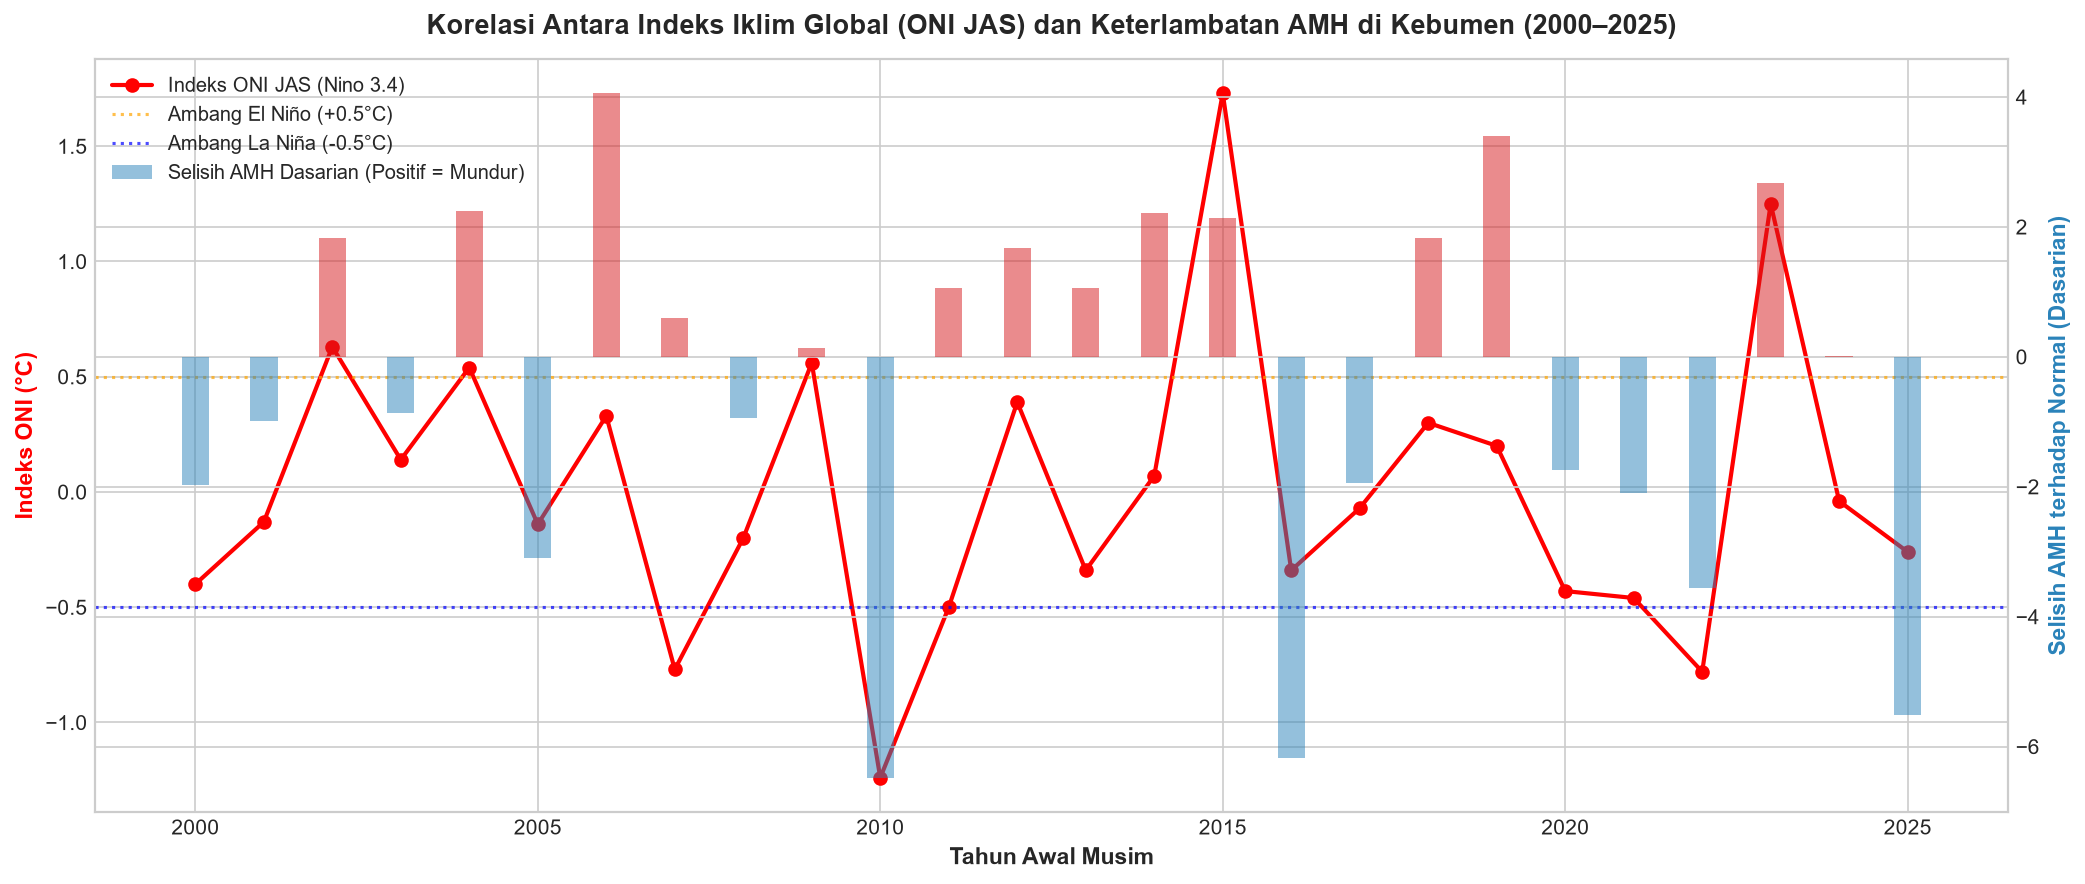

In [4]:
df_train = pd.read_csv(DATA_DIR / "dataset_training_prediksi_musim.csv")

# Agregasi selisih AMH tahunan terhadap ONI JAS
df_annual = df_train.groupby('tahun_awal').agg({
    'oni_jas': 'first',
    'dmi_sep': 'first',
    'amh_dasarian': 'mean',
    'selisih_dasarian': 'mean',
    'total_hujan_mh_mm': 'mean'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6), dpi=150)
ax2 = ax1.twinx()

ax1.plot(df_annual['tahun_awal'], df_annual['oni_jas'], color='red', marker='o', linewidth=2, label='Indeks ONI JAS (Nino 3.4)')
ax1.axhline(0.5, color='orange', linestyle=':', alpha=0.7, label='Ambang El Niño (+0.5°C)')
ax1.axhline(-0.5, color='blue', linestyle=':', alpha=0.7, label='Ambang La Niña (-0.5°C)')

bars = ax2.bar(df_annual['tahun_awal'], df_annual['selisih_dasarian'], width=0.4, alpha=0.5,
               color=['#d7191c' if x > 0 else '#2b83ba' for x in df_annual['selisih_dasarian']],
               label='Selisih AMH Dasarian (Positif = Mundur)')

ax1.set_xlabel("Tahun Awal Musim", fontsize=11, fontweight='bold')
ax1.set_ylabel("Indeks ONI (°C)", fontsize=11, color='red', fontweight='bold')
ax2.set_ylabel("Selisih AMH terhadap Normal (Dasarian)", fontsize=11, color='#2b83ba', fontweight='bold')
ax1.set_title("Korelasi Antara Indeks Iklim Global (ONI JAS) dan Keterlambatan AMH di Kebumen (2000–2025)", fontsize=13, fontweight='bold', pad=12)

# Menggabungkan legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.show()


## 3. Evaluasi Kinerja Model: Leave-One-Year-Out (LOYO) Cross-Validation
Sesuai Aturan Proyek 12, pengujian model **dilarang menggunakan random split** karena autokorelasi spasial dan temporal.
Sebagai gantinya, dilakukan **Leave-One-Year-Out (LOYO)**:
- Sebanyak 26 tahun diuji bergiliran (model dilatih pada 25 tahun, lalu menguji 1 tahun independen secara *out-of-fold*).
- Menghasilkan 676 prediksi independen bebas kebocoran data (*zero temporal data leakage*).


HASIL EVALUASI LEAVE-ONE-YEAR-OUT (LOYO) TAHUN 2000-2025 (676 PREDIKSI OOF)
Akurasi Kategori AMH (Maju / Sama / Mundur) : 58.28% (F1-Score Macro: 0.520)
Mean Absolute Error (MAE) Dasarian AMH       : 1.67 Dasarian (~16.7 hari)
Akurasi Sifat Hujan (Atas / Normal / Bawah)  : 62.43%


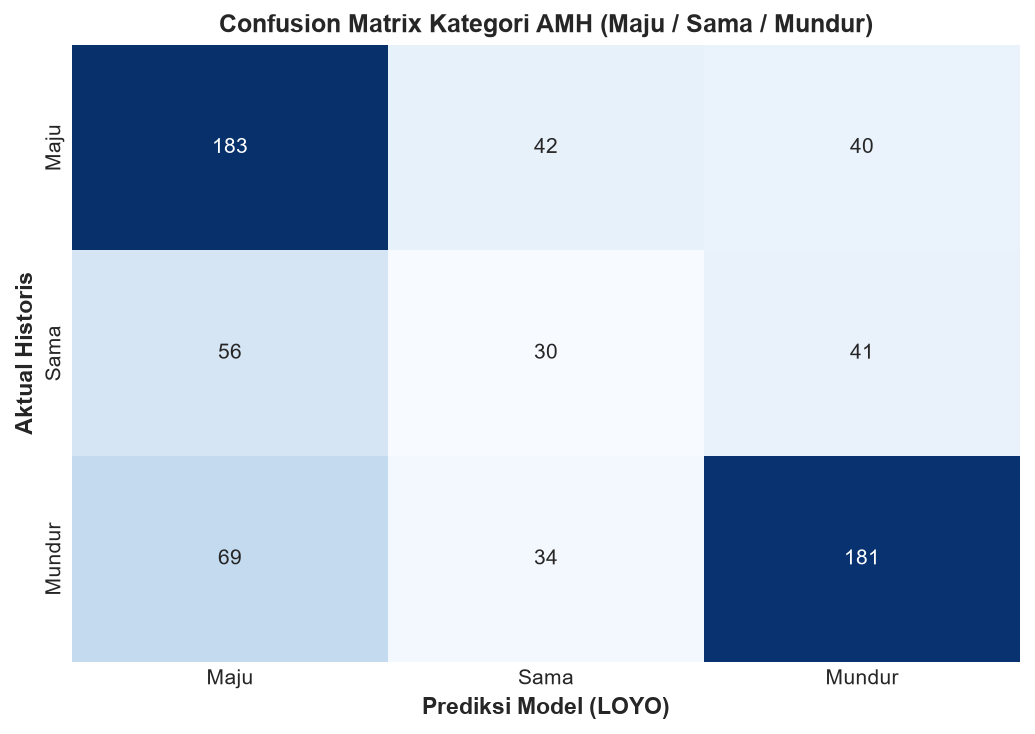

In [5]:
df_loyo = pd.read_csv(DATA_DIR / "hasil_evaluasi_loyo.csv")

acc_kat = accuracy_score(df_loyo['kategori_amh'], df_loyo['pred_kategori_amh'])
f1_kat = f1_score(df_loyo['kategori_amh'], df_loyo['pred_kategori_amh'], average='macro')
mae_das = mean_absolute_error(df_loyo['amh_dasarian'], df_loyo['pred_amh_dasarian'])
acc_sifat = accuracy_score(df_loyo['sifat_hujan'], df_loyo['pred_sifat_hujan'])

print("================================================================================")
print("HASIL EVALUASI LEAVE-ONE-YEAR-OUT (LOYO) TAHUN 2000-2025 (676 PREDIKSI OOF)")
print("================================================================================")
print(f"Akurasi Kategori AMH (Maju / Sama / Mundur) : {acc_kat * 100:.2f}% (F1-Score Macro: {f1_kat:.3f})")
print(f"Mean Absolute Error (MAE) Dasarian AMH       : {mae_das:.2f} Dasarian (~{mae_das * 10:.1f} hari)")
print(f"Akurasi Sifat Hujan (Atas / Normal / Bawah)  : {acc_sifat * 100:.2f}%")
print("================================================================================")

# Confusion Matrix
labels = ['Maju', 'Sama', 'Mundur']
cm = confusion_matrix(df_loyo['kategori_amh'], df_loyo['pred_kategori_amh'], labels=labels)

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
ax.set_xlabel("Prediksi Model (LOYO)", fontsize=11, fontweight='bold')
ax.set_ylabel("Aktual Historis", fontsize=11, fontweight='bold')
ax.set_title("Confusion Matrix Kategori AMH (Maju / Sama / Mundur)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Prakiraan Operasional Musim Hujan 2026/2027 (Kondisi El Niño Positif)
Menggunakan parameter global terkini 2026:
- Indeks ONI JAS: **+2.16** (Super El Niño)
- Indeks DMI Sep: **+0.42** (Positif)
- Prediktor atmosfer pra-musim dari ERA5-Land (Juli–September).

Berikut adalah prakiraan resolusi tinggi untuk seluruh 26 kecamatan di Kebumen:


In [6]:
df_2026 = pd.read_csv(DATA_DIR / "prakiraan_musim_2026_2027_kebumen.csv")

cols_display = [
    'kecamatan', 'normal_amh_label', 'prakiraan_amh_label',
    'perbandingan_terhadap_normal', 'probabilitas_mundur_pct',
    'prakiraan_sifat_hujan', 'prakiraan_puncak_label', 'rekomendasi_tanam_padi_mt1'
]
display(df_2026[cols_display])


,kecamatan,normal_amh_label,prakiraan_amh_label,perbandingan_terhadap_normal,probabilitas_mundur_pct,prakiraan_sifat_hujan,prakiraan_puncak_label,rekomendasi_tanam_padi_mt1
0,Ayah,Okt I,Nov III,Mundur,76.4,Bawah Normal,Des I,Des II
1,Buayan,Okt I,Nov III,Mundur,76.4,Bawah Normal,Des I,Des II
2,Puring,Okt II,Nov III,Mundur,77.5,Bawah Normal,Des I,Des II
3,Petanahan,Okt II,Nov III,Mundur,77.5,Bawah Normal,Des I,Des II
4,Klirong,Okt II,Nov III,Mundur,77.5,Bawah Normal,Des I,Des II
5,Buluspesantren,Okt III,Nov III,Mundur,77.5,Bawah Normal,Des I,Des II
6,Ambal,Okt III,Nov III,Mundur,79.0,Bawah Normal,Des I,Des II
7,Mirit,Okt III,Nov III,Mundur,90.4,Bawah Normal,Des I,Des II
8,Prembun,Okt III,Nov III,Mundur,79.0,Bawah Normal,Des I,Des II
9,Kutowinangun,Okt III,Nov III,Mundur,77.5,Bawah Normal,Des I,Des II


## 5. Galeri Peta Tematik Standar Publikasi 16:9
Berikut adalah 6 peta tematik resolusi tinggi (300 DPI, rasio 16:9) yang dihasilkan oleh modul kartografi otomatis:


Menampilkan: Peta_1_Normal_AMH_Kebumen.png


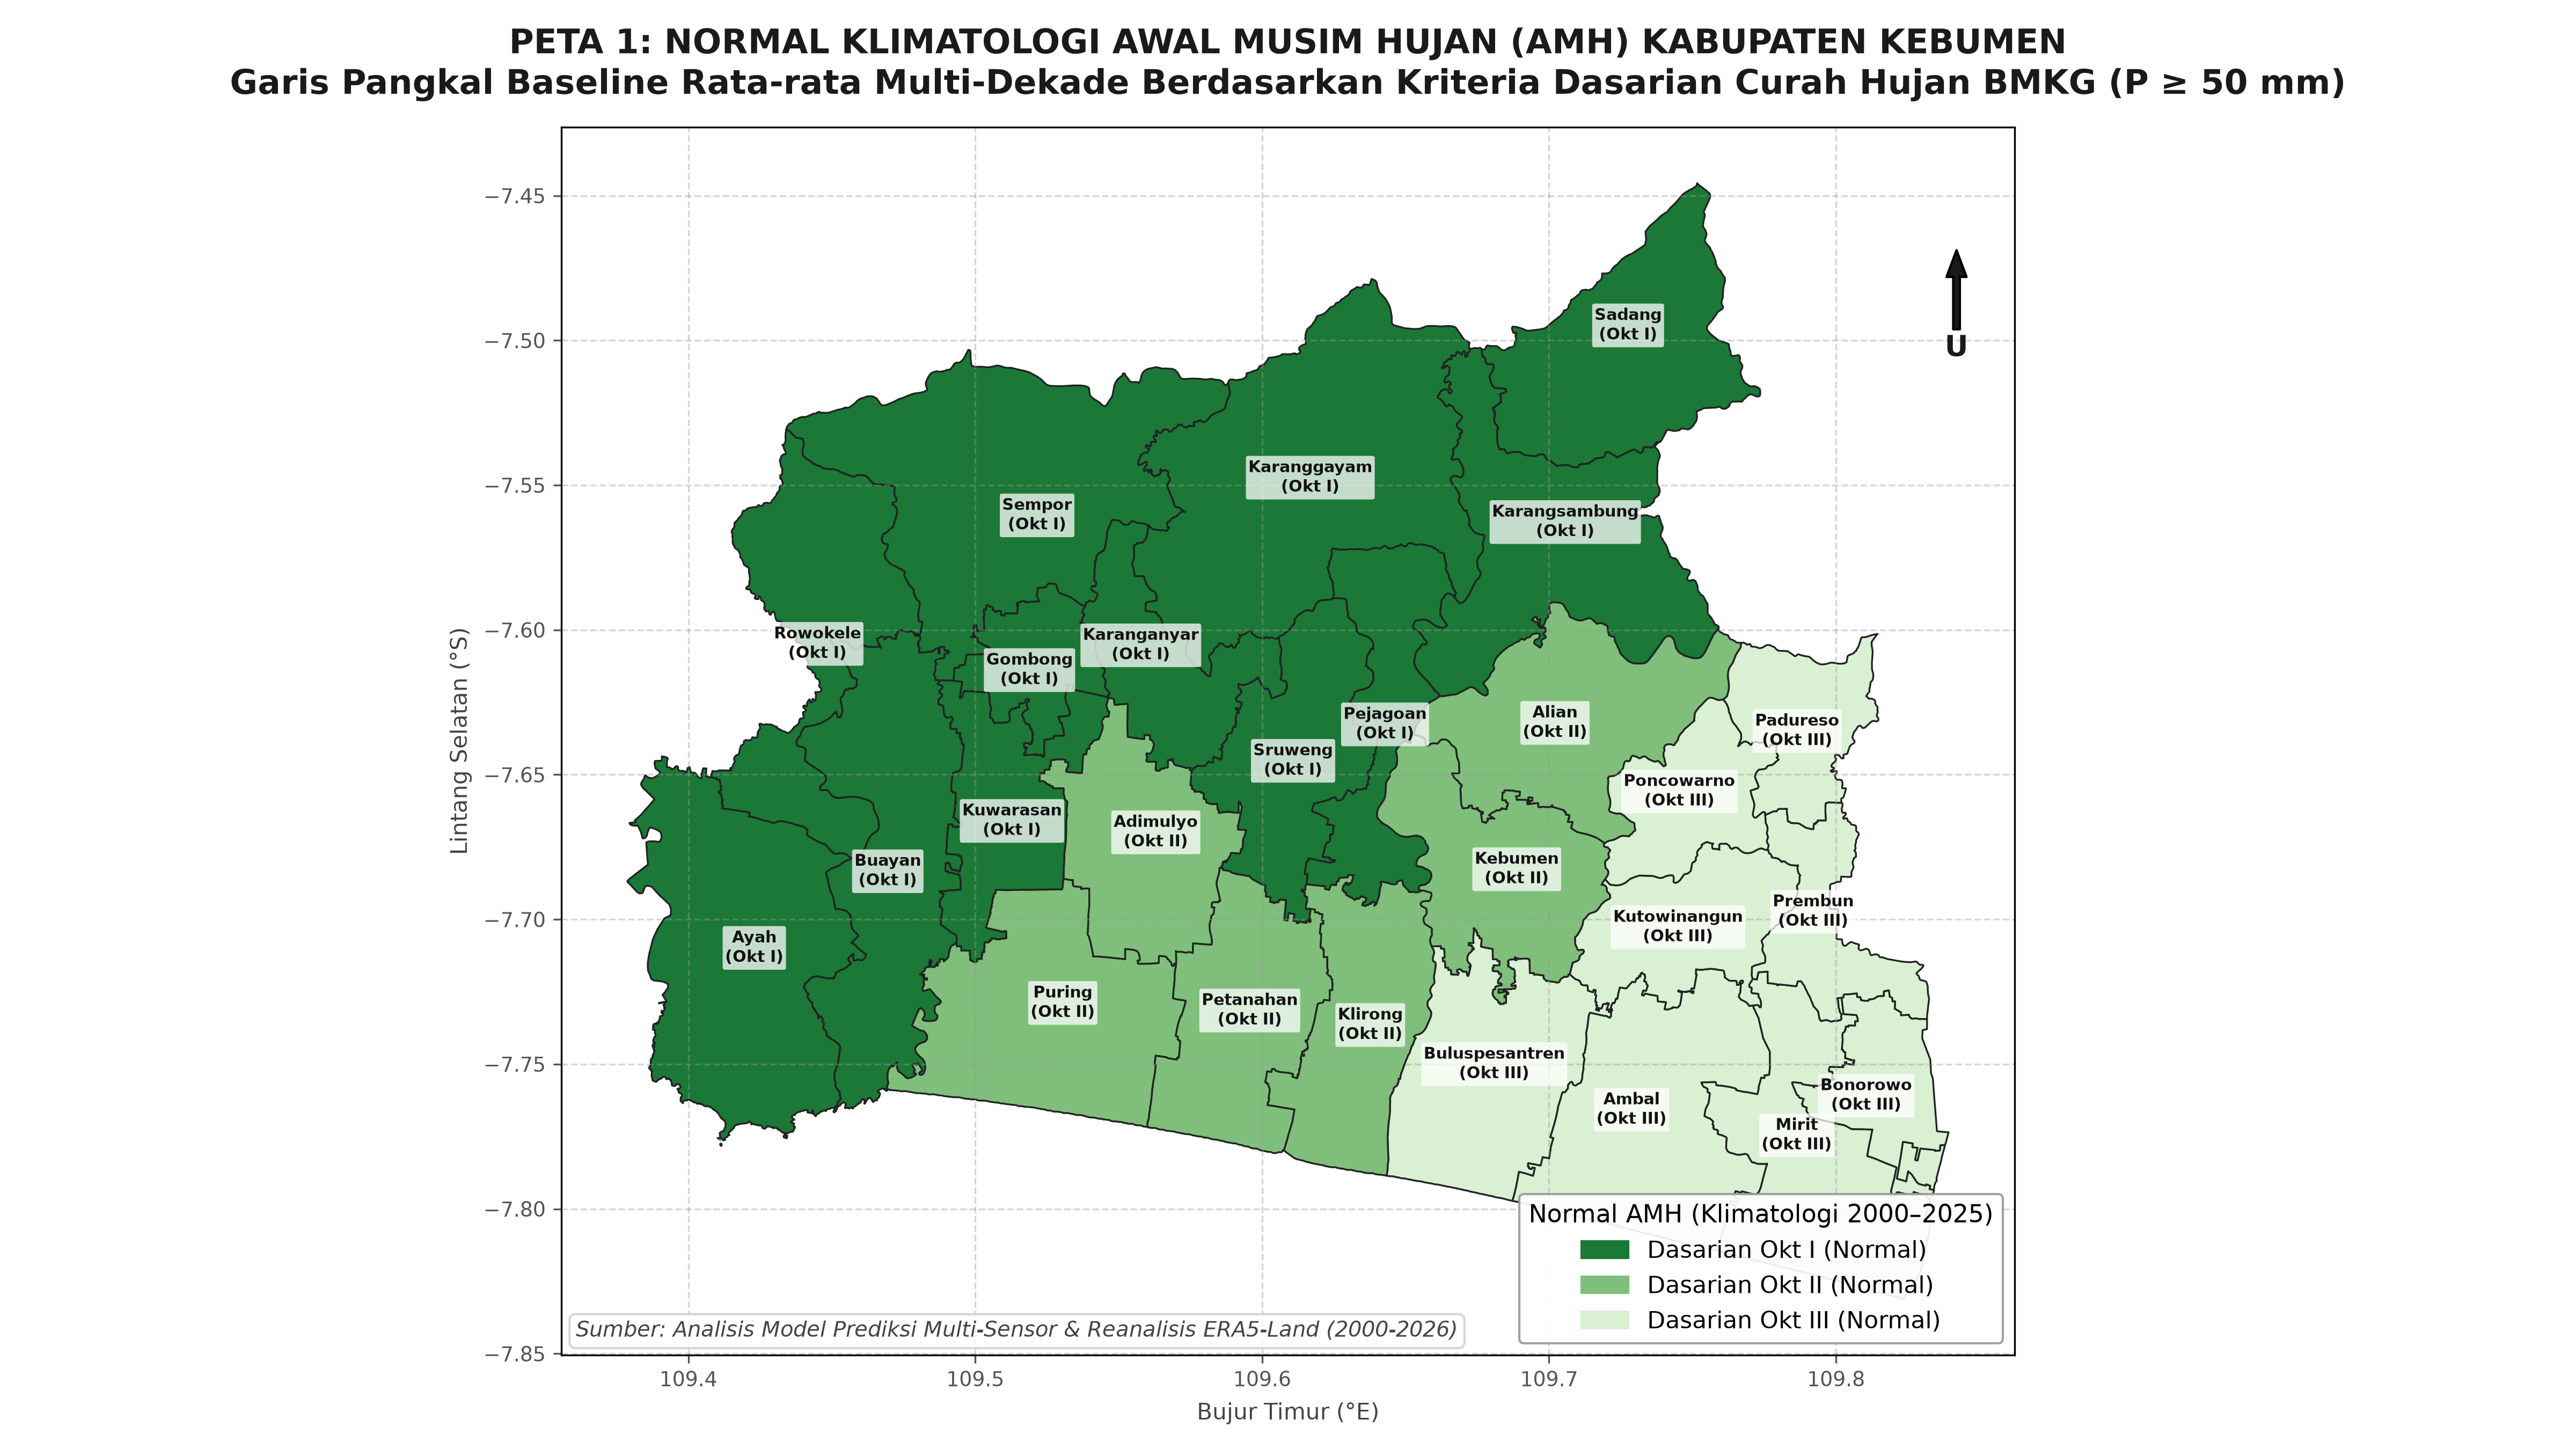

Menampilkan: Peta_2_Prakiraan_AMH_2026_2027.png


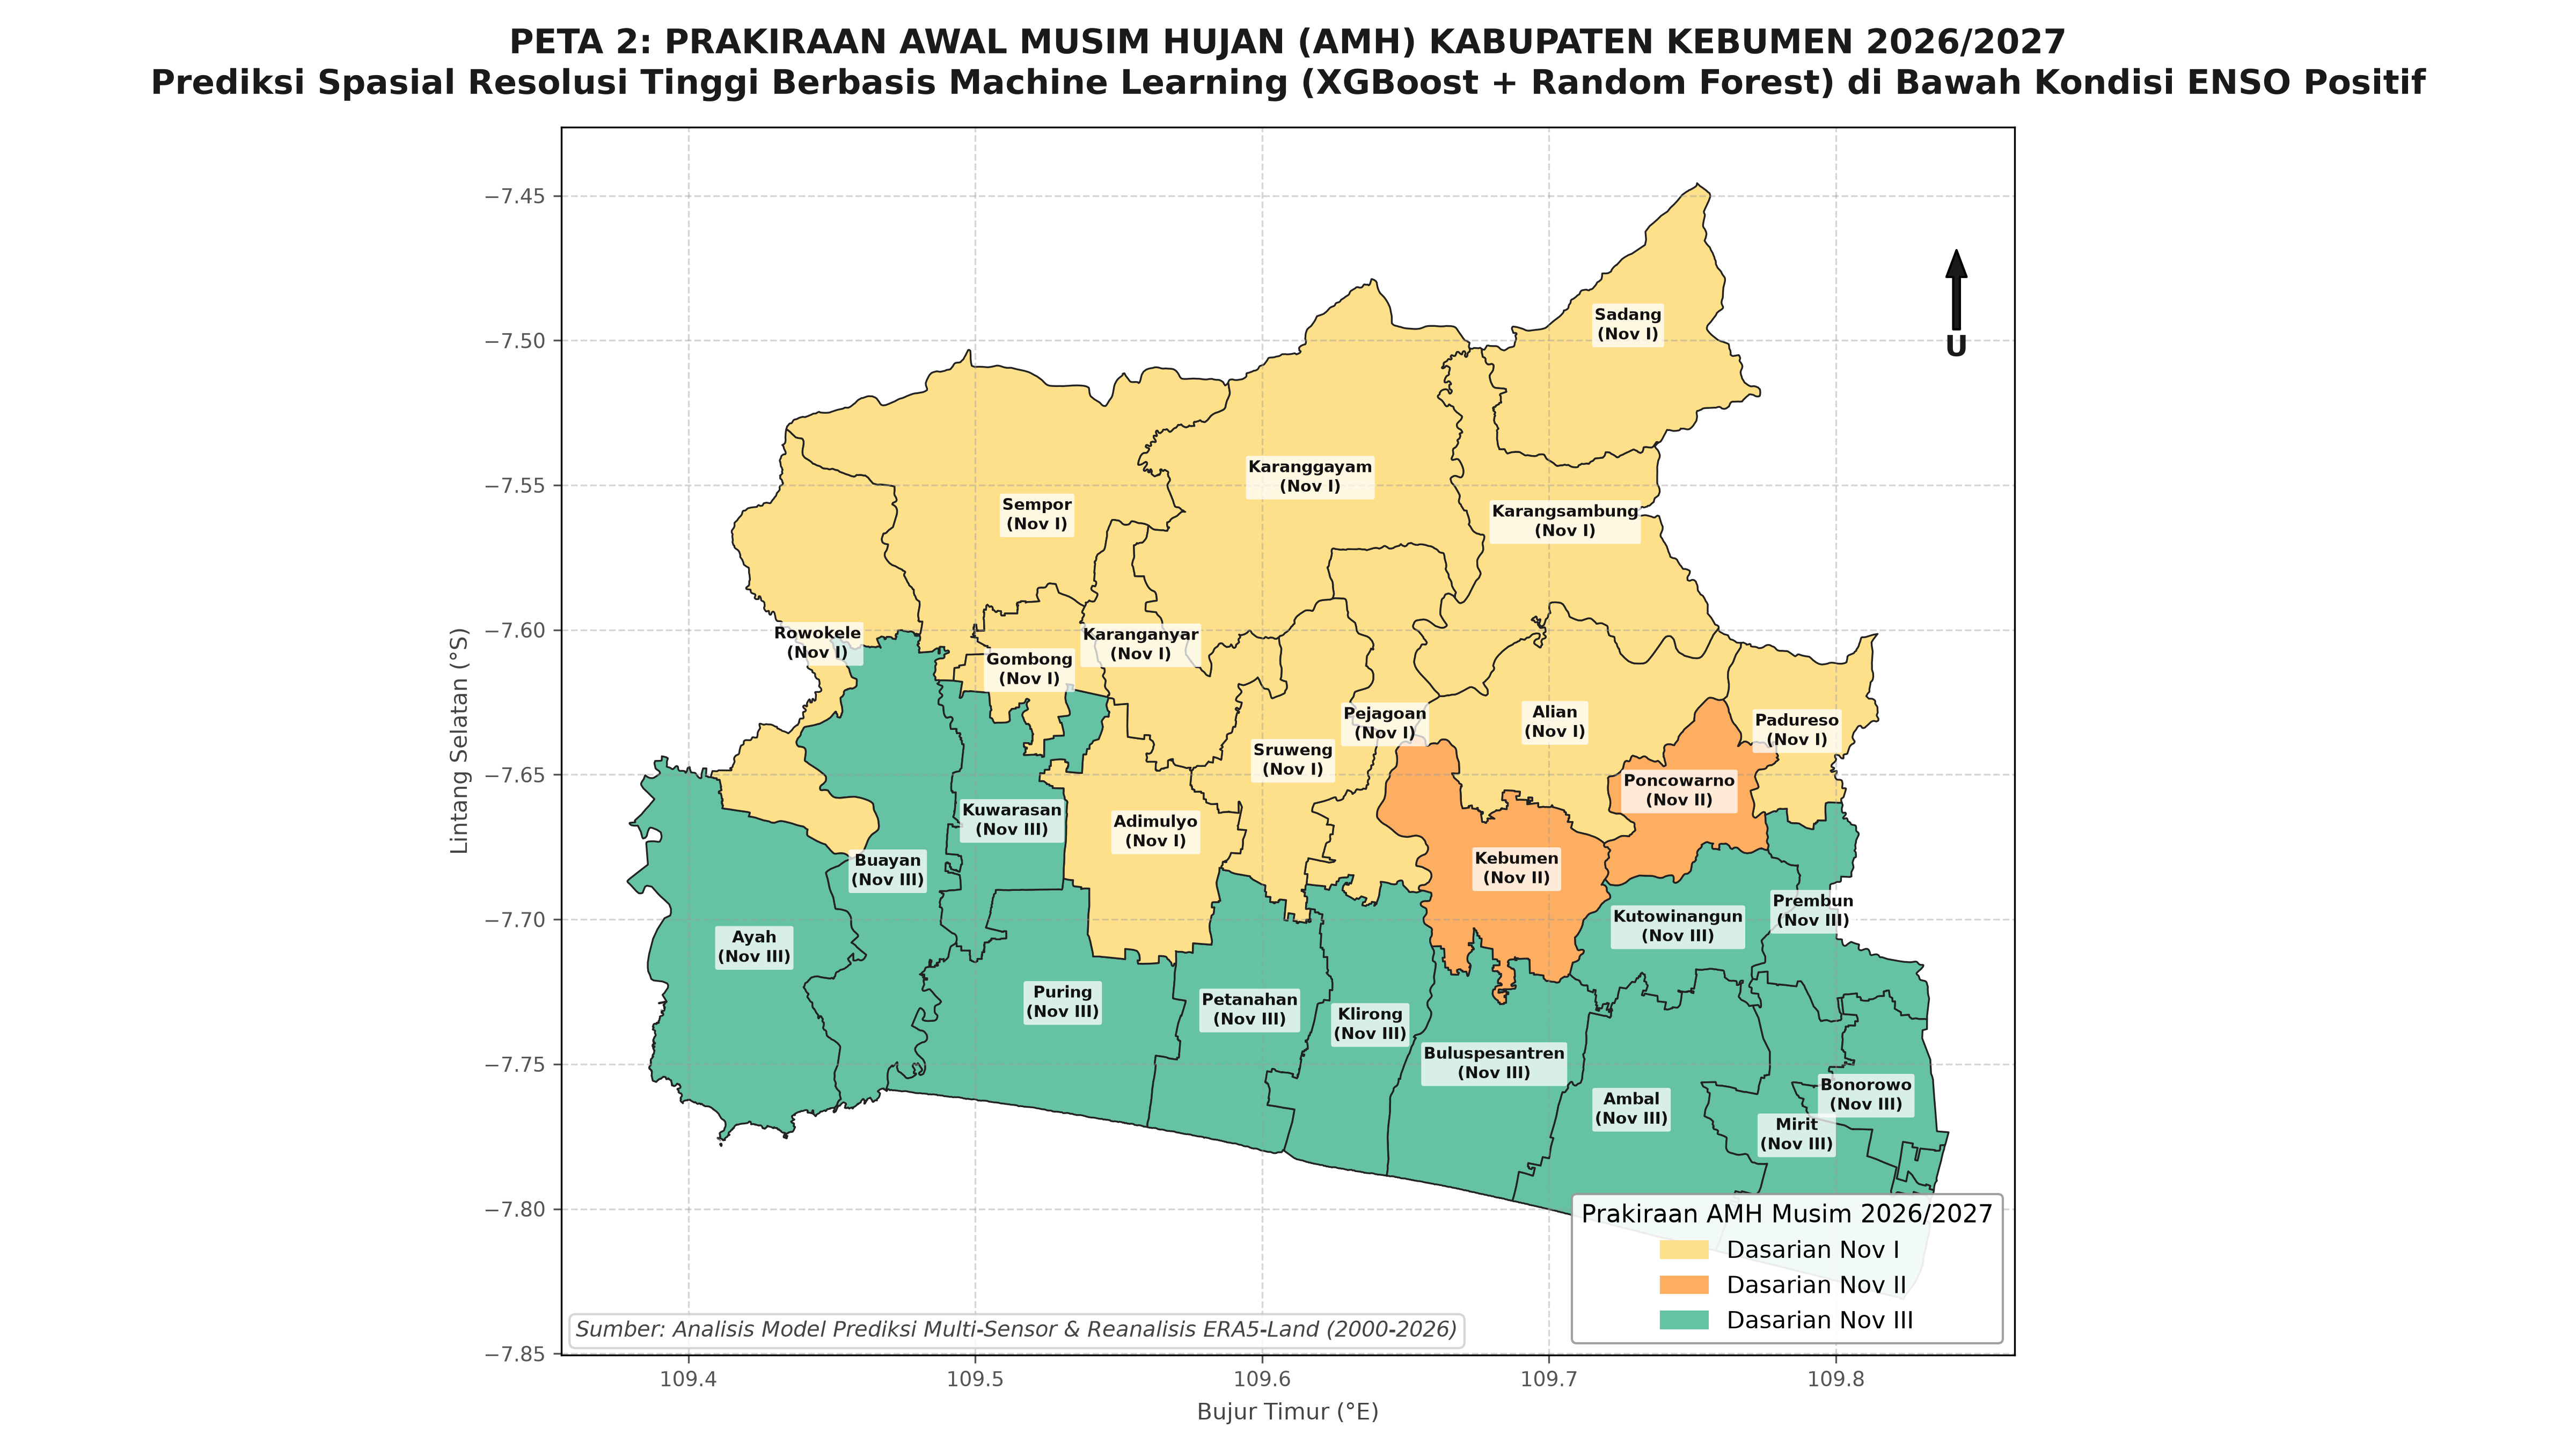

Menampilkan: Peta_3_Perbandingan_Terhadap_Normal.png


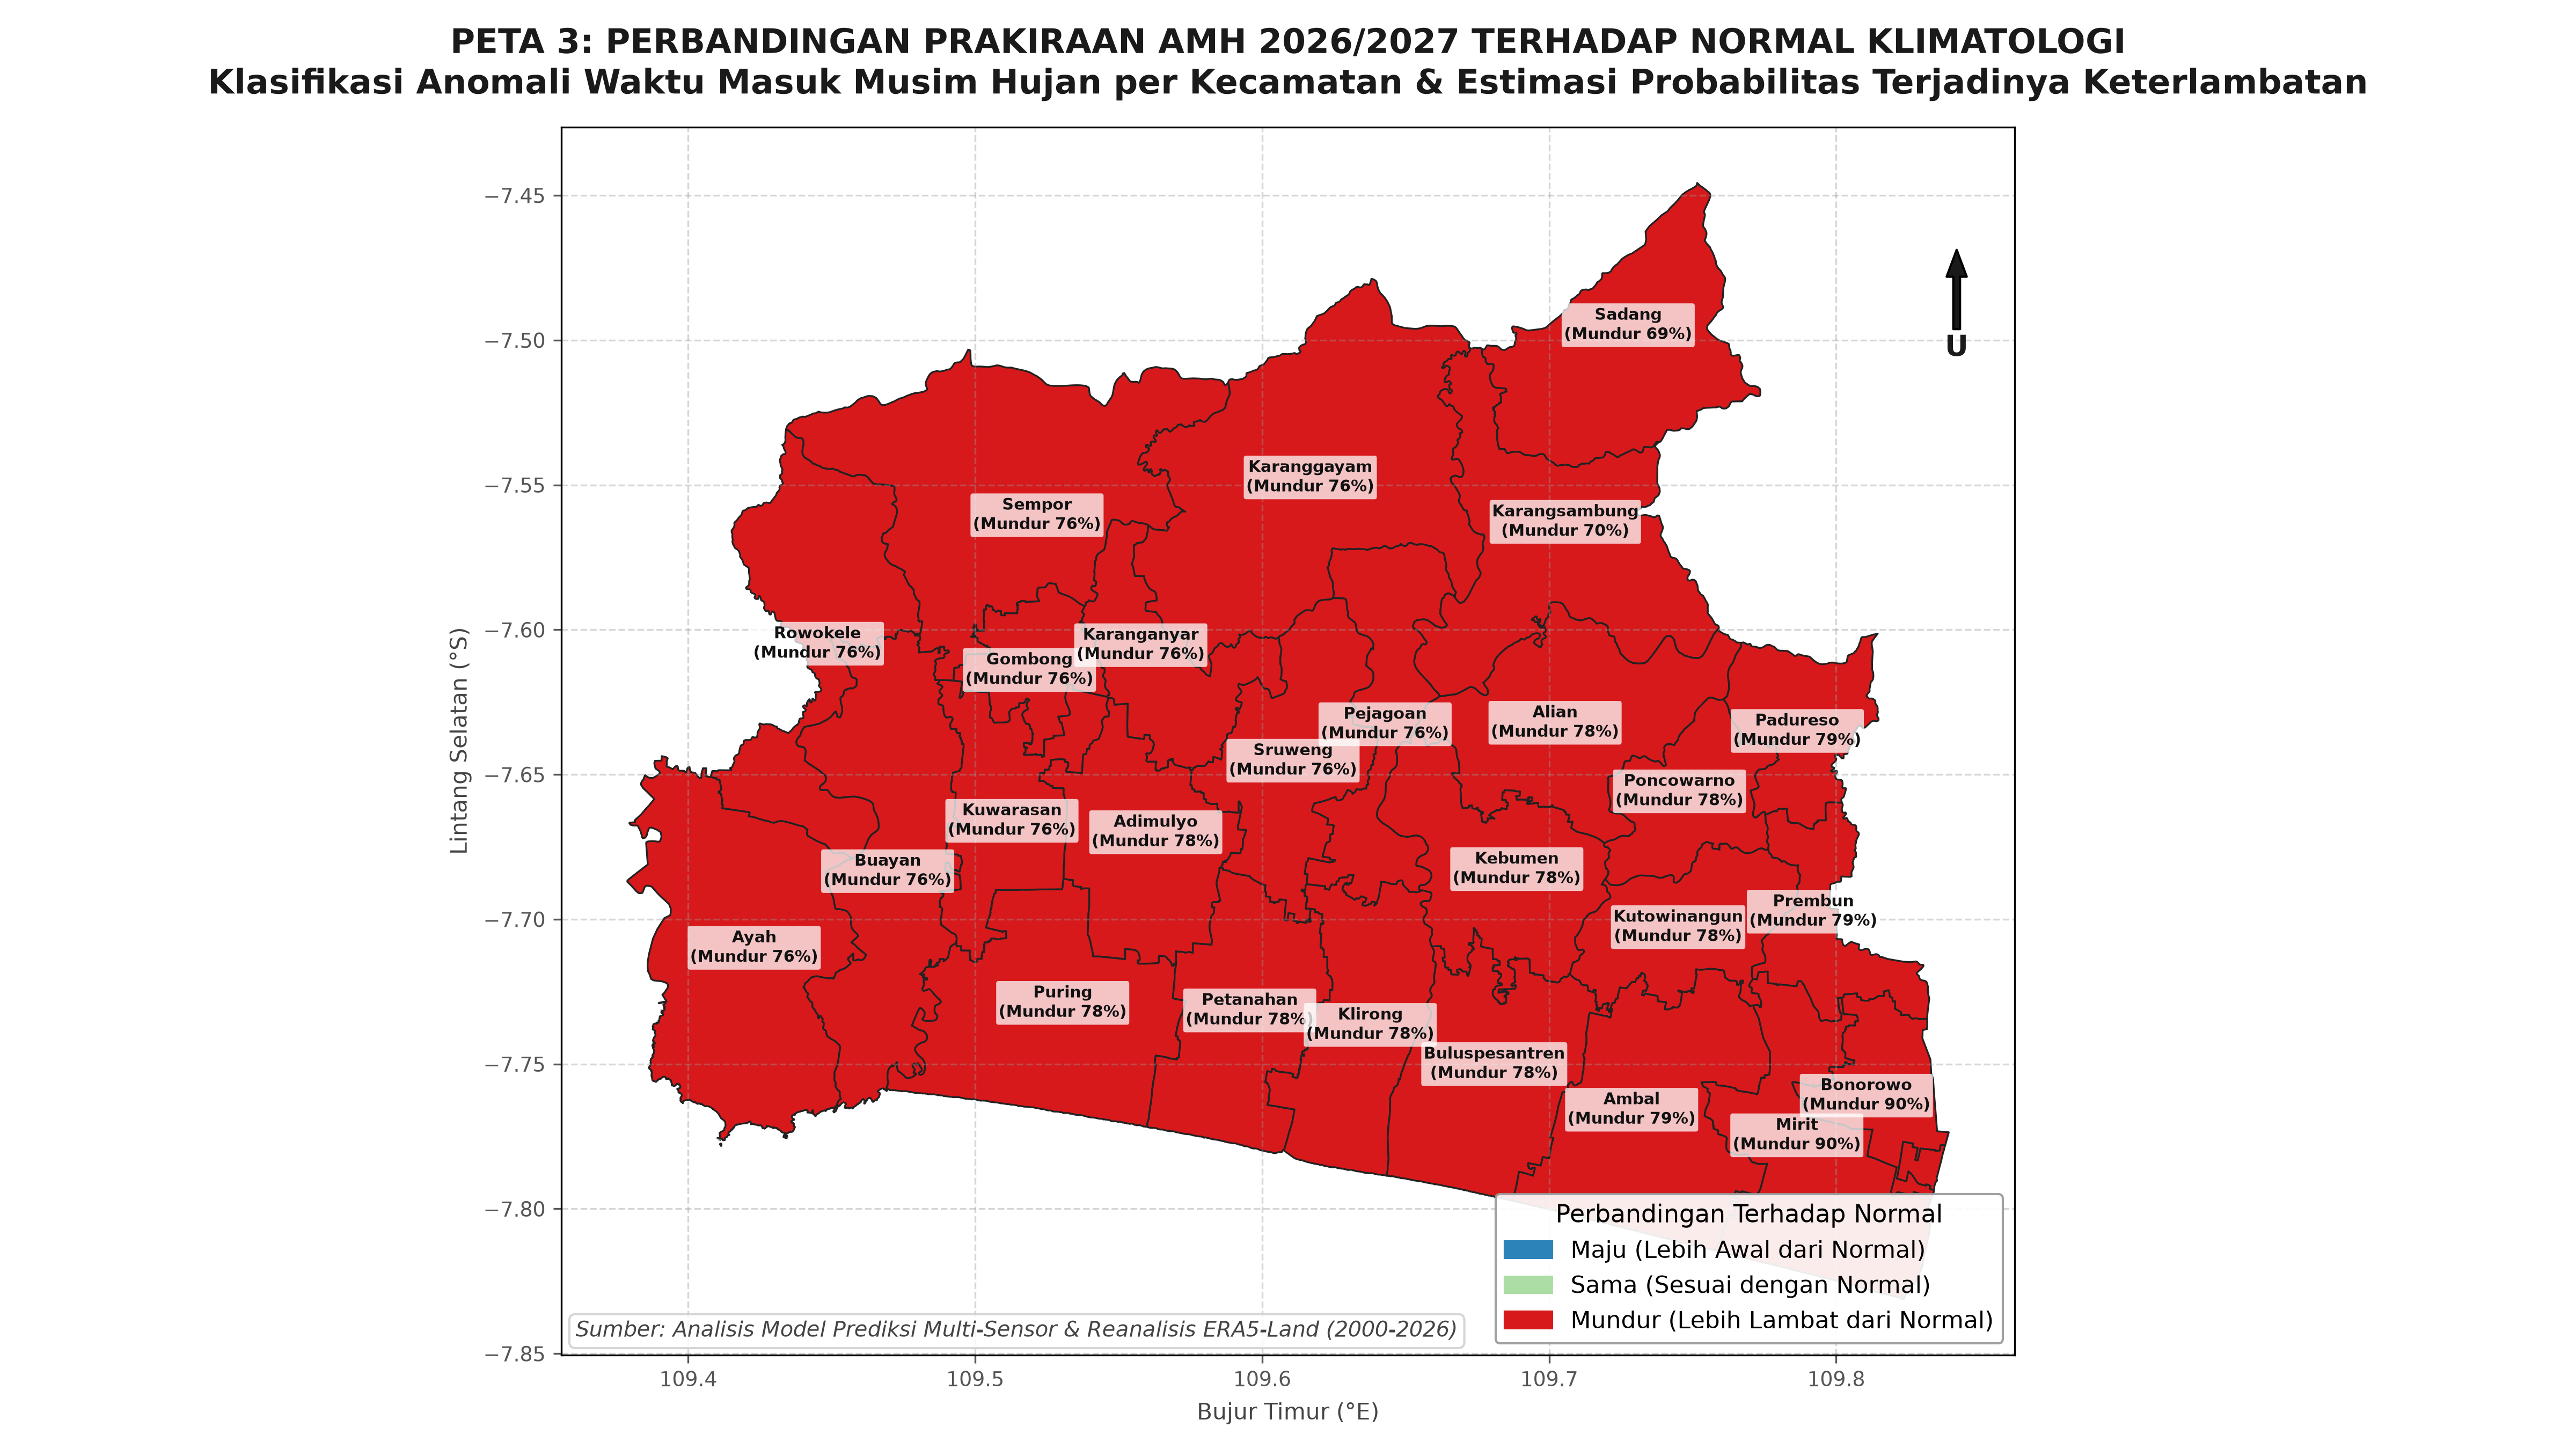

Menampilkan: Peta_4_Prakiraan_Sifat_Hujan.png


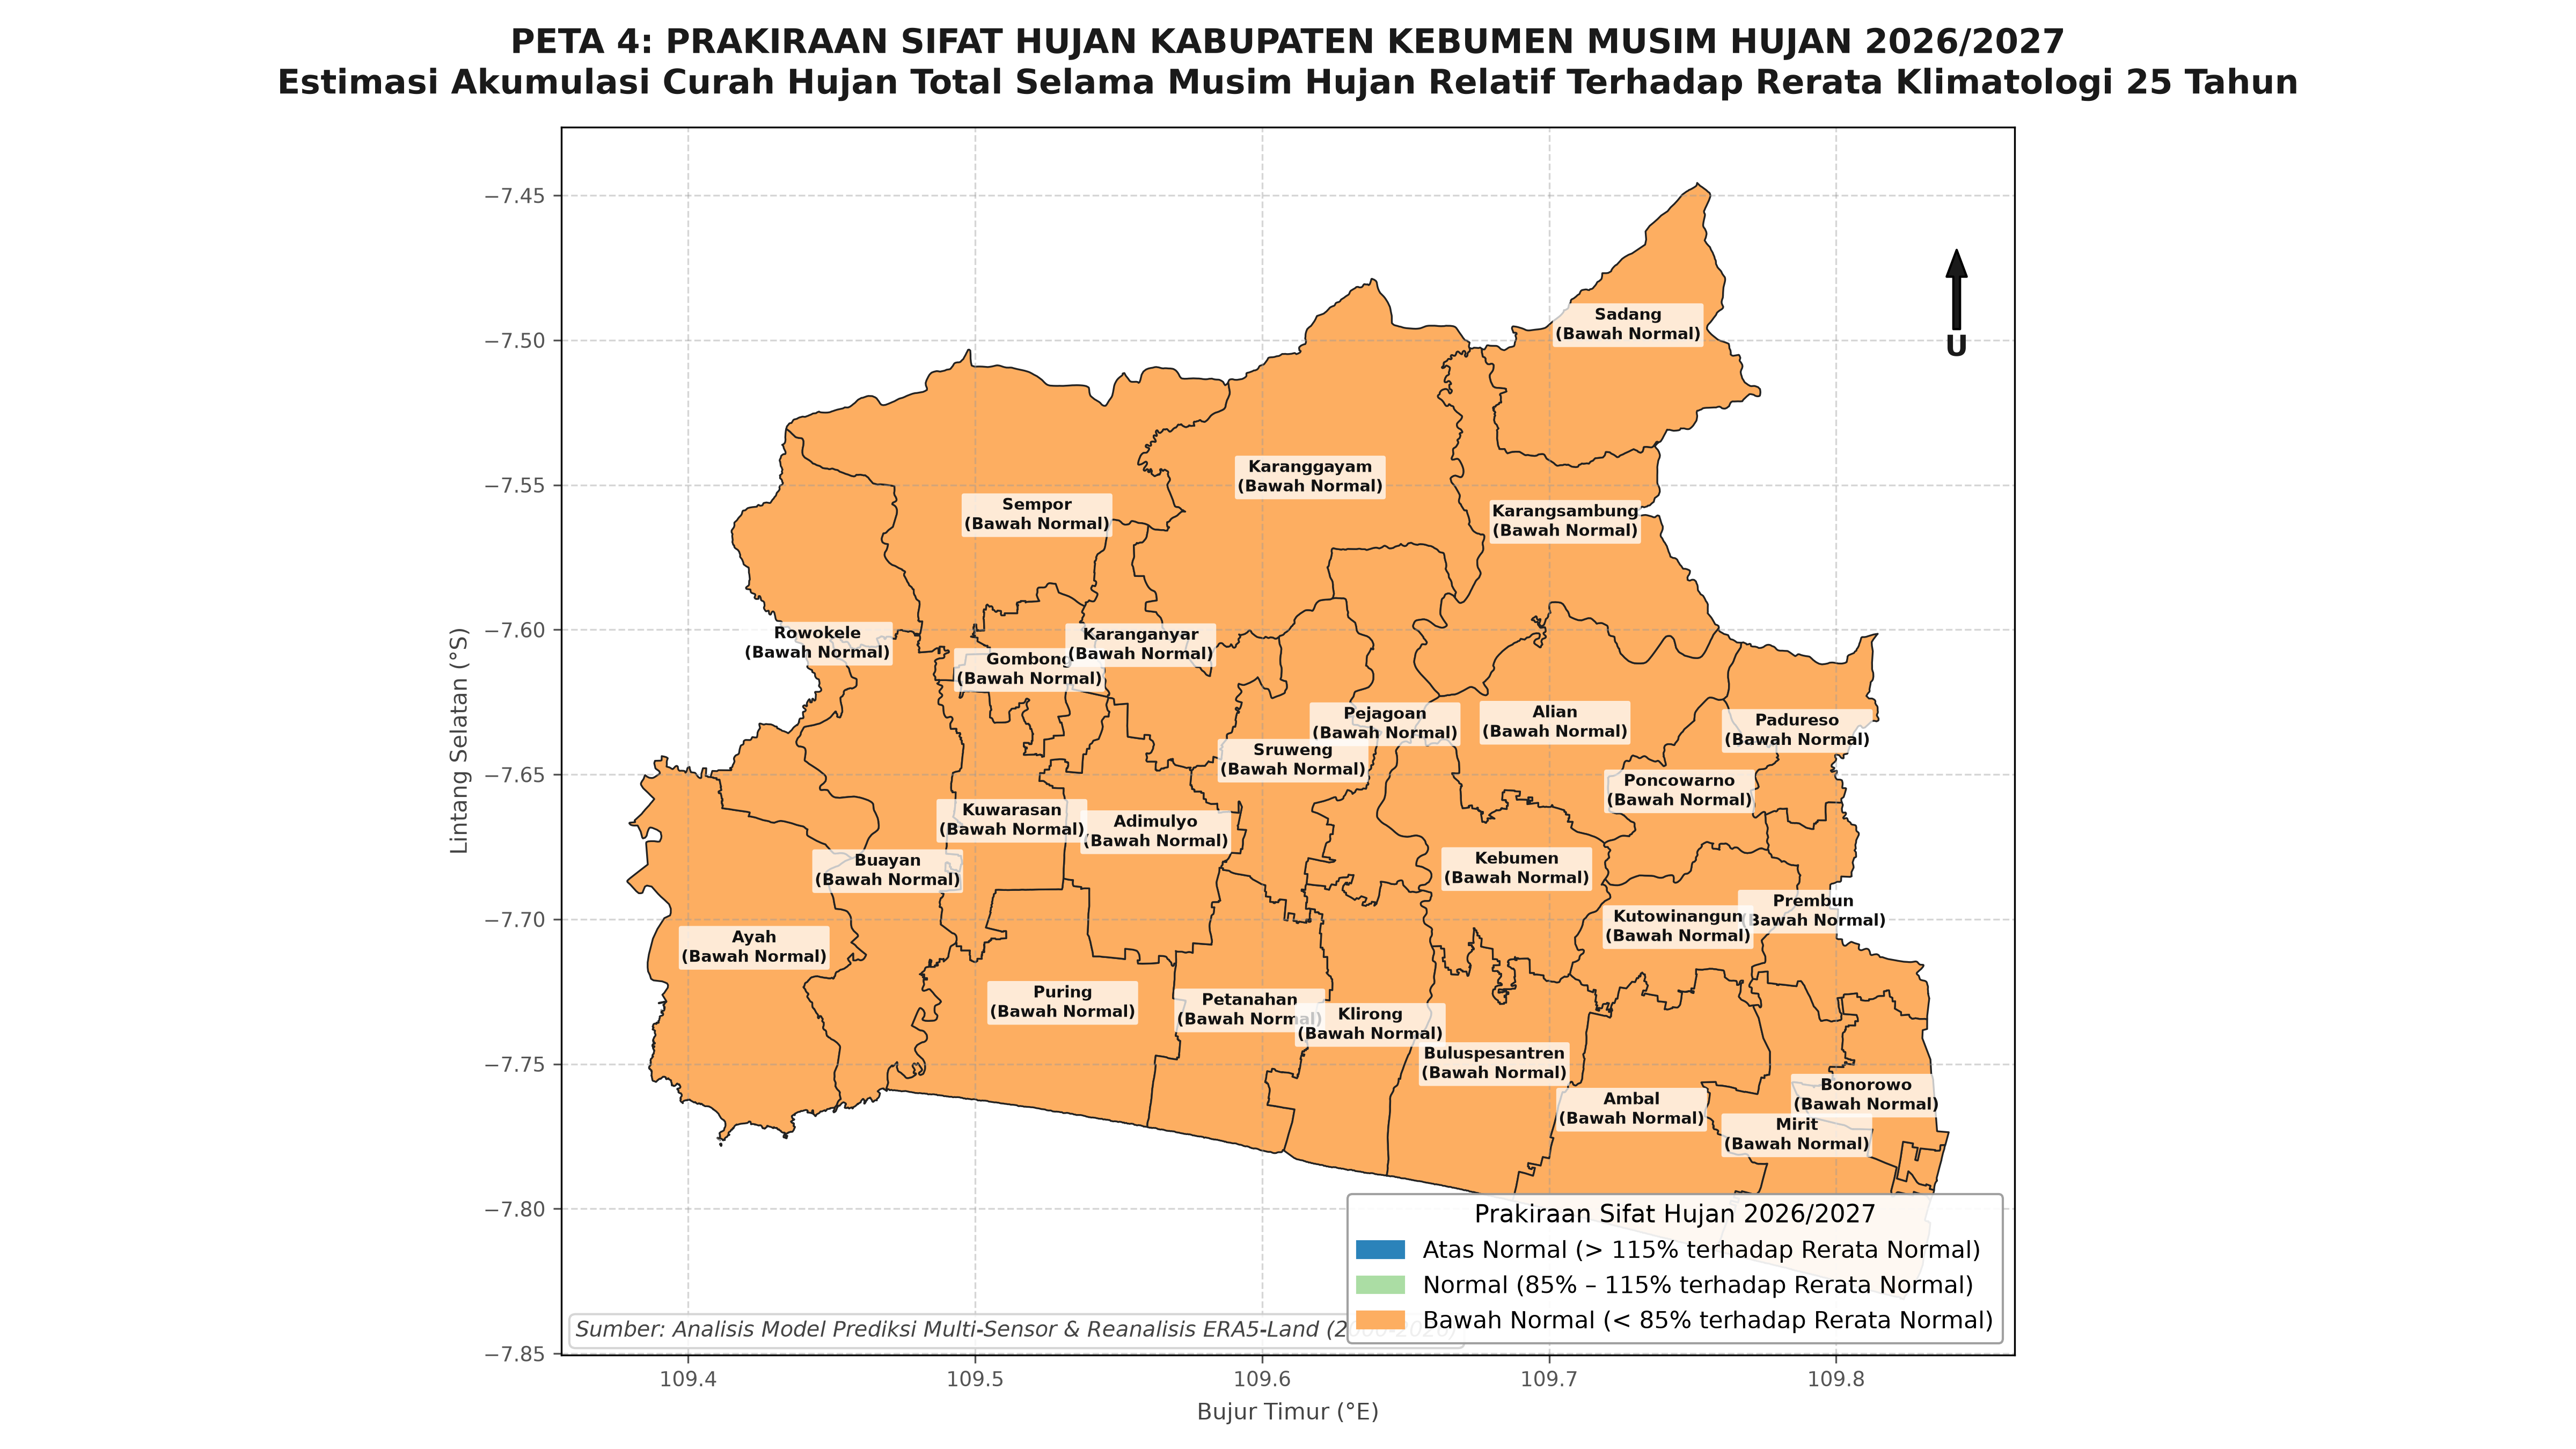

Menampilkan: Peta_5_Prakiraan_Puncak_Musim_Hujan.png


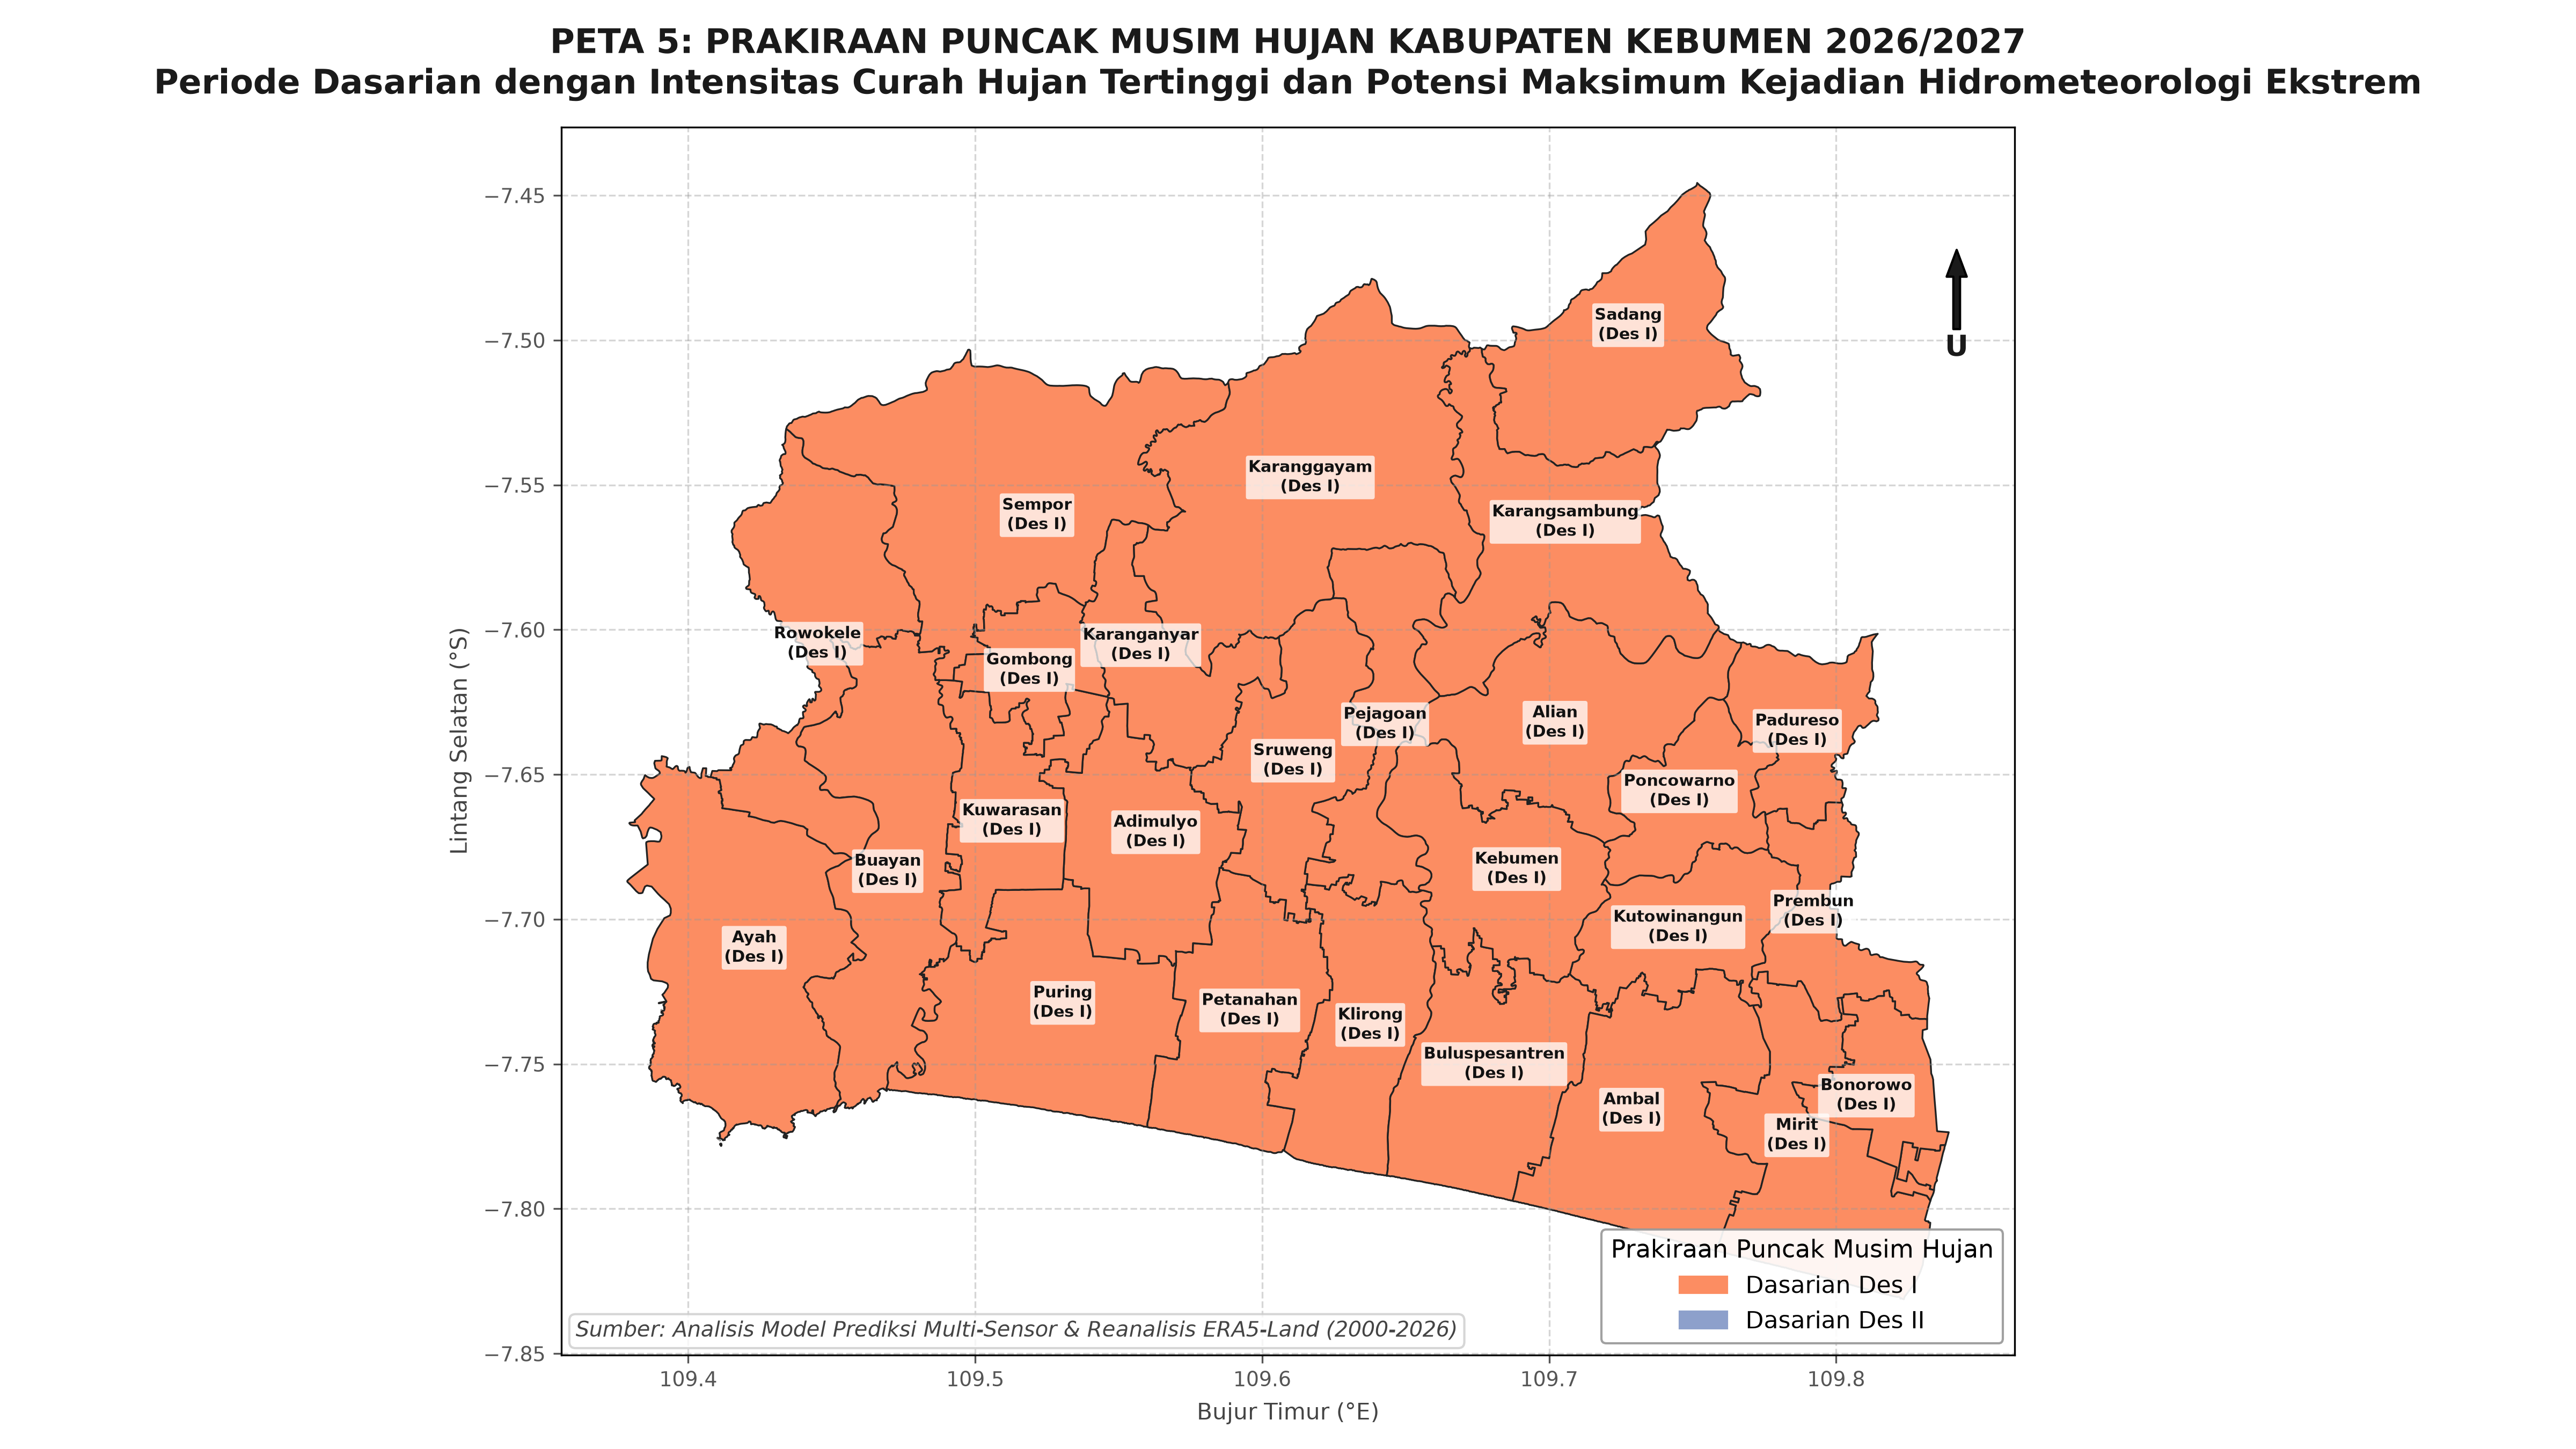

Menampilkan: Peta_6_Zonasi_Kalender_Tanam_Pertanian.png


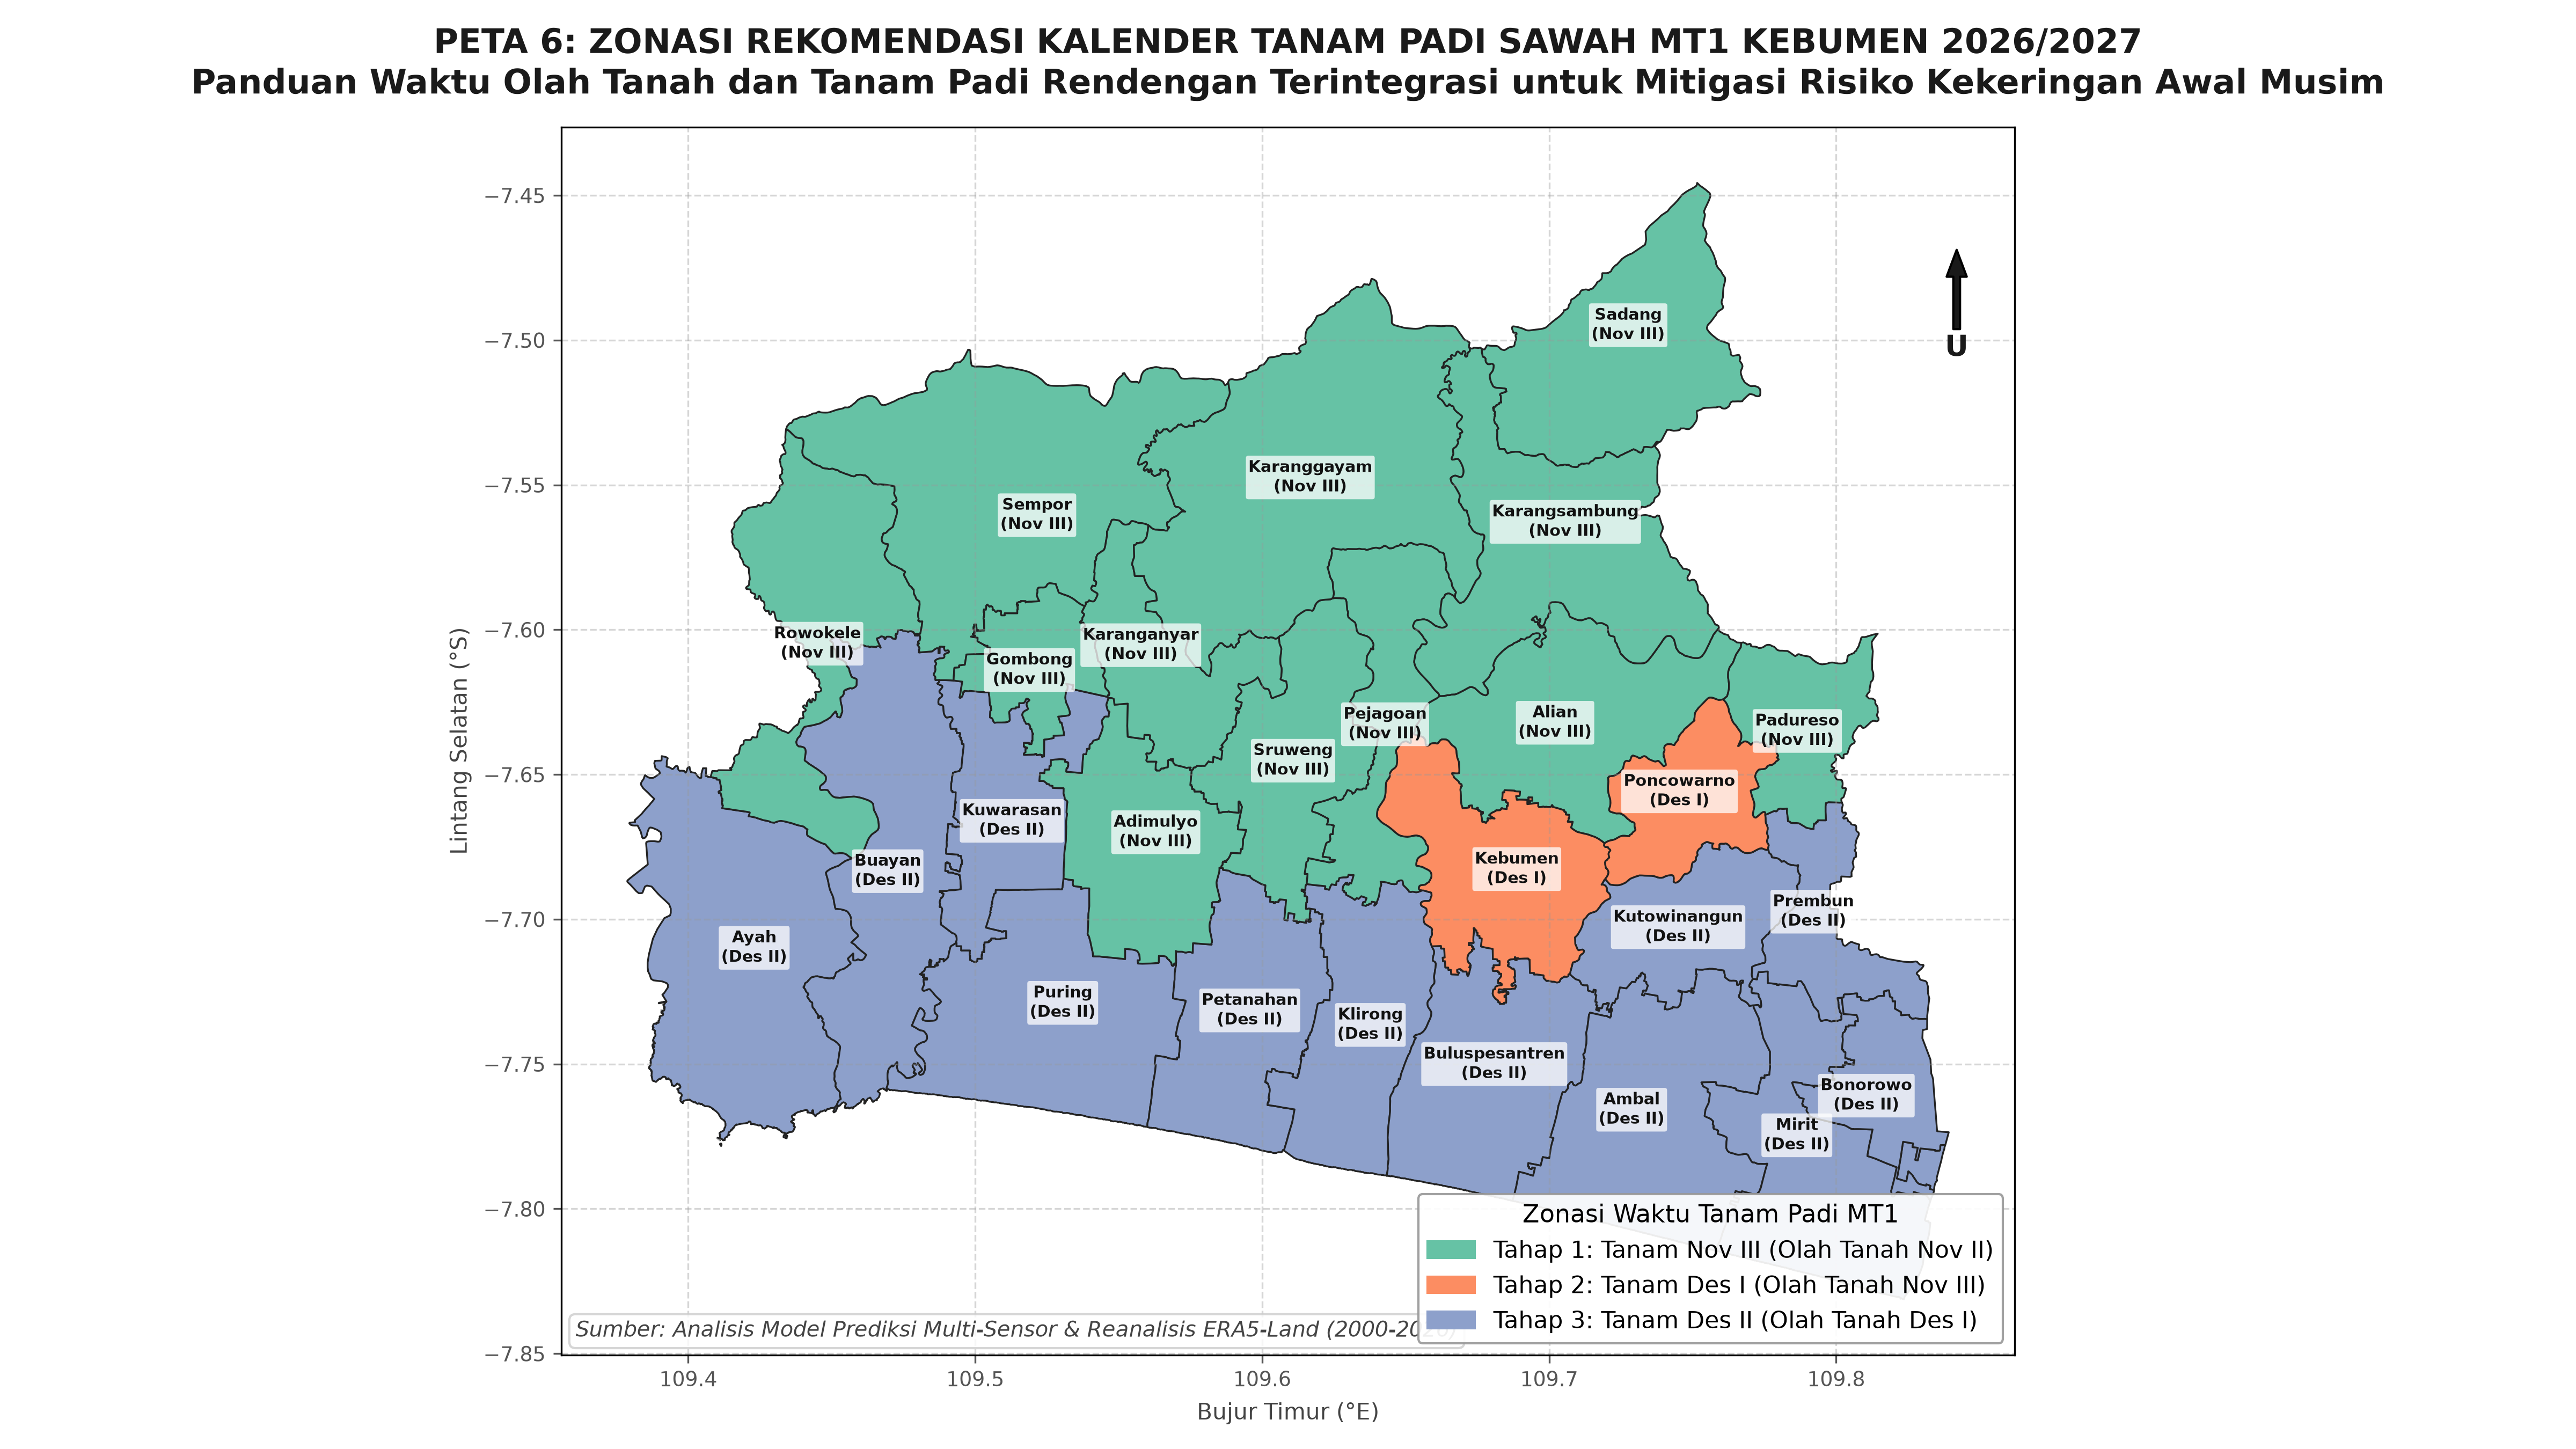

In [7]:
peta_files = [
    "Peta_1_Normal_AMH_Kebumen.png",
    "Peta_2_Prakiraan_AMH_2026_2027.png",
    "Peta_3_Perbandingan_Terhadap_Normal.png",
    "Peta_4_Prakiraan_Sifat_Hujan.png",
    "Peta_5_Prakiraan_Puncak_Musim_Hujan.png",
    "Peta_6_Zonasi_Kalender_Tanam_Pertanian.png"
]

for p in peta_files:
    p_path = PLOTS_DIR / p
    if p_path.exists():
        print(f"Menampilkan: {p}")
        display(Image(filename=str(p_path), width=900))
    else:
        print(f"Peta {p} belum ditemukan di {PLOTS_DIR}.")


## 6. Matriks Rekomendasi Kebijakan Sektoral Kabupaten Kebumen (2026/2027)

| Sektor Terkait | Dampak Utama Terprediksi | Tindakan Mitigasi & Adaptasi Prioritas | Lokasi Prioritas / Target Kecamatan |
| :--- | :--- | :--- | :--- |
| **Pertanian Tanaman Pangan (Dinas Pertanian)** | Musim hujan **MUNDUR** hingga Nov I–III, sifat hujan **BAWAH NORMAL**, defisit air awal musim. | 1. Tunda persemaian padi MT1 hingga dasarian rekomendasi (Nov III atau Des I/II).<br>2. Gunakan varietas padi tahan kekeringan/umur genjah (Inpari 32, Ciherang, M400).<br>3. Terapkan pola olah tanah basah minimum dan hemat air (AWD - *Alternate Wetting and Drying*). | Ayah, Buayan, Puring, Petanahan, Klirong, Buluspesantren, Ambal, Mirit. |
| **Pengelolaan Sumber Daya Air (DPUPR & BBWS)** | Pengisian volume waduk melambat akibat defisit curah hujan Oktober-November. | 1. Terapkan giliran gilir-giring air irigasi Daerah Irigasi (DI) Sempor dan DI Wadaslintang.<br>2. Perketat efisiensi bukaan pintu air saluran primer dan sekunder.<br>3. Normalisasi saluran tersier dan embung penampung air hujan sebelum Desember I. | Wilayah kerja DI Sempor (Gombong, Karanganyar, Adimulyo) & DI Wadaslintang Barat. |
| **Penanggulangan Bencana (BPBD Kebumen)** | Puncak musim hujan terkonsentrasi di **Desember I**, potensi hujan intensitas tinggi dalam durasi singkat. | 1. Siaga darurat tanah longsor pada zona terjal formasi batuan lipatan utara.<br>2. Pasang/uji alat deteksi dini pergerakan tanah (*Early Warning System* - EWS).<br>3. Bersihkan sumbatan sampah pada muara sungai Luk Ulo, Telomoyo, dan Cingcingguling menjelang Desember. | Sadang, Karanggayam, Karangsambung, Alian, Pejagoan, Sempor. |

---
*Notebook ini disusun secara otomatis sebagai bagian dari Framework Prediksi Musim Hujan Resolusi Tinggi Kabupaten Kebumen.*
